# Advanced Lapse Prediction Using XGBoost
### Probabilistic Model for Non-Life Insurance Flood Risk

**Authors:** Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III  
**Notebook:** 07B — Advanced Cancellation and Non-Renewal Model

## 1. Research Objective and Method
This notebook evaluates whether XGBoost improves policy-year lapse probability estimates relative to the naive, logistic regression, and Random Forest benchmarks. The analysis includes a starting model, hyperparameter tuning, probability calibration, and a missingness sensitivity analysis.

The target is **`LAPSE`**: 1 indicates a qualifying cancellation during the policy-year or non-renewal at its end; 0 indicates no qualifying lapse. Population exclusions and label definitions follow notebooks 03 and 04.

| Analysis stage | Policy-year starts | Purpose |
|---|---|---|
| Training | 2014–2020 | Fit preprocessing and model parameters |
| Rolling-origin folds | Validation years 2017–2020 | Select hyperparameters using earlier training years |
| Development evaluation (`test`) | 2021–2022 | Compare model versions and select the XGBoost pipeline |
| Final holdout (`valid`) | 2023–August 2024 | Evaluate the frozen pipeline once |

**Training data (same as 06b and the random forest):** the final XGBoost models learn from **all 26.8M training policy-years** (2014–2020), read in 06b's 28 chunks. Only two steps use samples, exactly as in 06b: the preprocessing (medians, category levels, donor pools) is fitted on a 1M-row training sample, and the tuning uses a 500k-row sample.

**Primary evaluation:** log loss, Brier score, and calibration. **Additional evaluation:** ROC-AUC, average precision (PR-AUC/AP), and top-decile capture. No class rebalancing is applied.

**Inputs:** `data/processed/features.parquet`, `docs/feature_plan.csv`, and the fixed cleaning rules in `src/features.py`. Insurance data and trained models are not bundled with this notebook. Numerical results and figures are generated by execution on the processed dataset.

## 2. Libraries and Configuration
The notebook runs from the project repository and uses the existing processed data. The software environment requires Python, XGBoost 2.0 or later, DuckDB, pandas, NumPy, scikit-learn, Matplotlib, PyArrow, and joblib.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import importlib.metadata
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import joblib
import xgboost as xgb

from sklearn.model_selection import ParameterGrid
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    log_loss, brier_score_loss, roc_auc_score, average_precision_score
)
from IPython.display import display, Markdown

In [2]:
# Fixed settings used across the analysis.
SEED = 42
TARGET = 'LAPSE'
PREP_ROWS = 1_000_000   # training sample for fitting the preprocessing ONLY (as in 06b); the final models use every training row
TUNE_ROWS = 500_000     # tuning sample for the rolling-origin folds (as in 06b and the random forest)
N_TREES = 200
N_THREADS = 12          # processor cores for XGBoost and DuckDB (the laptop has 14; two are left for the system)
N_CHUNKS = 28           # the training split is read in 06b's 28 chunks; the test split is scored in 28 pieces
CHECK_YEARS = [2017, 2018, 2019, 2020]

# The final holdout is reserved until model selection is complete. Keep this False: the holdout (2023 - Aug 2024)
# is opened once, for every model together, in notebooks 08a/08b.
RUN_FINAL_HOLDOUT = False
RUN_SENSITIVITY = True

BASE_PARAMS = dict(
    objective='binary:logistic', eval_metric='logloss', tree_method='hist',
    enable_categorical=True, n_estimators=N_TREES, learning_rate=0.05,
    max_depth=4, min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=5, scale_pos_weight=1, n_jobs=N_THREADS, random_state=SEED
)

In [3]:
# Locate the project and define its input and output folders.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/features.py').exists()), None)
assert ROOT is not None, 'The notebook must run inside the Flood Risk repository.'
sys.path.insert(0, str(ROOT))
from src.features import apply_fixed_rules

FEATURES_FILE = ROOT / 'data/processed/features.parquet'
SHARED_IDS_FILE = ROOT / 'data/processed/samples/lapse_train_ids.parquet'
REPORTS = ROOT / 'reports'
MODEL_DIR = ROOT / 'data/processed/models/lapse_xgb'
PRED_DIR = ROOT / 'data/processed/predictions'
CACHE_DIR = ROOT / 'data/processed/cache/lapse_xgb_train'   # prepared training chunks (temporary; removed in Section 13)

for folder in [REPORTS, MODEL_DIR, PRED_DIR, SHARED_IDS_FILE.parent]:
    folder.mkdir(parents=True, exist_ok=True)
assert FEATURES_FILE.exists(), 'Required input missing: data/processed/features.parquet.'

In [4]:
# Use one plotting style and record the software versions.
plt.rcParams.update({
    'figure.figsize': (8, 4.5), 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False
})
versions = {name: importlib.metadata.version(name) for name in
            ['xgboost', 'duckdb', 'pandas', 'numpy', 'scikit-learn']}
display(pd.Series(versions, name='Version').to_frame())

,Version
xgboost,3.4.1
duckdb,2.0.0
pandas,2.3.3
numpy,2.4.4
scikit-learn,1.9.0


## 3. Input Data and Approved Features
Only features approved in notebook 05 are included. Identifiers, split labels, policy-year labels, and the target are excluded from the predictors. DuckDB queries the Parquet file directly to limit memory usage.

In [5]:
# Read the approved feature list and missing-value rules.
plan = pd.read_csv(ROOT / 'docs/feature_plan.csv')
plan = plan[plan['use'].astype(str).str.lower().eq('true')].copy()

FEATS = plan['feature'].tolist()
NUMS = plan.loc[plan['kind'].eq('num'), 'feature'].tolist()
CATS = plan.loc[plan['kind'].eq('cat'), 'feature'].tolist()
FLAGS = plan.loc[plan['kind'].eq('flag'), 'feature'].tolist()
MISSING_PLAN = plan.set_index('feature')['missing_plan'].fillna('').to_dict()
RANDOM_COLS = [f for f in NUMS if 'NO missing flag' in MISSING_PLAN[f]]
ACS_COLS = [f for f in RANDOM_COLS if f.startswith('acs_')]

assert not set(FEATS) & {TARGET, 'period_id', 'period_year', 'split'}
print(f'Approved predictors: {len(NUMS)} numeric, {len(CATS)} categorical, {len(FLAGS)} flags.')

Approved predictors: 43 numeric, 12 categorical, 13 flags.


In [6]:
# Open the processed dataset and select the eligible lapse population.
con = duckdb.connect()
con.execute("SET memory_limit='8GB'")   # the laptop has 24 GB; the rest is left for Python and XGBoost
con.execute(f'SET threads={N_THREADS}')
con.from_parquet(str(FEATURES_FILE)).create_view('source_features')
con.execute('CREATE VIEW lapse_pop AS SELECT * FROM source_features WHERE in_pop_lapse')

SELECT_COLS = ', '.join(['period_id', 'period_year'] + FEATS + [TARGET])
columns = {row[0] for row in con.execute('DESCRIBE lapse_pop').fetchall()}
assert set(FEATS + [TARGET, 'period_id', 'period_year', 'split']).issubset(columns)

In [7]:
# Summarize the training and development populations.
summary = con.sql(f"""
    SELECT split, MIN(period_year) AS first_year, MAX(period_year) AS last_year,
           COUNT(*) AS policy_years, AVG({TARGET}) AS lapse_rate
    FROM lapse_pop
    WHERE split IN ('train', 'test')
    GROUP BY split
    ORDER BY first_year
""").df()
display(summary.assign(lapse_rate=summary['lapse_rate'].map('{:.2%}'.format)))

,split,first_year,last_year,policy_years,lapse_rate
0,train,2014,2020,26758825,13.84%
1,test,2021,2022,7105637,12.02%


In [8]:
# Check the agreed time splits and binary target.
invalid_train = con.sql("""SELECT COUNT(*) FROM lapse_pop
    WHERE split='train' AND period_year NOT BETWEEN 2014 AND 2020""").fetchall()[0][0]
invalid_test = con.sql("""SELECT COUNT(*) FROM lapse_pop
    WHERE split='test' AND period_year NOT BETWEEN 2021 AND 2022""").fetchall()[0][0]
invalid_labels = con.sql(f"""SELECT COUNT(*) FROM lapse_pop
    WHERE split IN ('train','test')
      AND ({TARGET} IS NULL OR {TARGET} NOT IN (0,1))""").fetchall()[0][0]

assert invalid_train == invalid_test == invalid_labels == 0
print('Input schema, time splits, and target checks passed.')

Input schema, time splits, and target checks passed.


### 3.1 Data Preparation Functions
These reusable functions keep the model-training cells short. The seven features with suspected outcome-related missingness use training-only donor values and stable policy-year keys. ACS values share a donor row to retain their observed joint relationships. Other features follow the approved fill and missing-indicator rules; categorical variables use native XGBoost support.

The function definitions are grouped below and may appear collapsed in compatible notebook viewers. Stable imputation reduces an obvious missingness marker; it does not establish that all leakage has been removed.

In [9]:
def load_rows(split, where="TRUE"):
    assert split in {"train", "test", "valid"}
    return con.sql(f"SELECT {SELECT_COLS} FROM lapse_pop WHERE split='{split}' AND {where}").df()

In [10]:
def stable_draw(ids, key, pool_size):
    # IDs control reproducible draws only; they never enter the model.
    return np.fromiter((int.from_bytes(hashlib.sha256(
        f"{SEED}|{key}|{value}".encode()).digest()[:8], 'little') % pool_size
        for value in ids.astype(str)), dtype=np.int64, count=len(ids))

In [11]:
def fit_preprocessor(frame, features=FEATS):
    clean = apply_fixed_rules(frame)
    state = {"features": list(features), "medians": {}, "levels": {}, "pools": {}}
    for f in features:
        if f in CATS:
            state['levels'][f] = sorted(clean[f].dropna().astype(str).unique().tolist()) + ['__MISSING__']
        else:
            values = pd.to_numeric(clean[f], errors='coerce').astype('float64').replace([np.inf, -np.inf], np.nan)  # float64: boolean flags can't be filled with 0
            state['medians'][f] = float(values.median()) if values.notna().any() else 0.0
    # Use complete donor rows for the ACS group, never test or holdout rows.
    groups = ([ACS_COLS] if ACS_COLS else []) + [[f] for f in RANDOM_COLS if f not in ACS_COLS]
    for group in groups:
        active = [f for f in group if f in features]
        if not active:
            continue
        donors = clean[active].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
        if donors.empty:
            raise ValueError(f"No complete training donors for {active}; exclude this group or review the data.")
        donors = donors.sample(n=min(100_000, len(donors)), random_state=SEED).to_numpy()
        state['pools']['|'.join(active)] = (active, donors)
    return state

In [12]:
def transform_features(frame, state):
    clean = apply_fixed_rules(frame).reset_index(drop=True)
    result = pd.DataFrame(index=clean.index)
    random_values = {}
    for key, (group, pool) in state['pools'].items():
        selected = stable_draw(clean['period_id'], key, len(pool))
        for j, f in enumerate(group):
            random_values[f] = pool[selected, j]
    for f in state['features']:
        if f in CATS:
            values = clean[f].astype('string').fillna('__MISSING__')
            result[f] = pd.Categorical(values, categories=state['levels'][f])
            continue
        values = pd.to_numeric(clean[f], errors='coerce').astype('float64').replace([np.inf, -np.inf], np.nan)  # float64: boolean flags can't be filled with 0
        rule = MISSING_PLAN.get(f, '')
        if f in random_values:
            values = values.fillna(pd.Series(random_values[f], index=clean.index))
        elif rule.startswith('fill 99'):
            values = values.fillna(99)
        elif f in FLAGS or rule.startswith('fill 0'):
            result[f + '__missing'] = values.isna().astype('float32')
            values = values.fillna(0)
        else:
            if '+ missing flag' in rule:
                result[f + '__missing'] = values.isna().astype('float32')
            values = values.fillna(state['medians'][f])
        result[f] = values.astype('float32')
    assert not result.drop(columns=[f for f in CATS if f in result], errors='ignore').isna().any().any()
    return result

## 4. Preprocessing Sample and Full Training Data
The final models learn from **every** training row (Section 4.1). The preprocessing (medians, category levels and donor pools for the seven random-fill features) is fitted on a fixed **1M-row training sample**, as in 06b; the same sample also supplies the 500k-row tuning sample (Section 6). A training-ID manifest keeps this sample identical across runs.

In [13]:
# The 1M-row preprocessing sample: reuse the training-ID manifest when available.
if SHARED_IDS_FILE.exists():
    con.from_parquet(str(SHARED_IDS_FILE)).create_view('shared_ids')
    prep_sample = load_rows('train', 'period_id IN (SELECT period_id FROM shared_ids)')
    expected = con.sql('SELECT COUNT(*) FROM shared_ids').fetchall()[0][0]
    assert len(prep_sample) == expected, 'Training IDs do not match the input dataset.'
    sample_origin = 'Existing training-ID manifest'
else:
    prep_sample = con.sql(f"""SELECT * FROM
        (SELECT {SELECT_COLS} FROM lapse_pop WHERE split='train')
        USING SAMPLE reservoir({PREP_ROWS} ROWS) REPEATABLE ({SEED})""").df()
    prep_sample[['period_id']].to_parquet(SHARED_IDS_FILE, index=False)
    sample_origin = 'New manifest of the preprocessing sample'

prep_sample = prep_sample.sort_values('period_id').reset_index(drop=True)
assert prep_sample['period_id'].is_unique and prep_sample[TARGET].nunique() == 2
sample_hash = hashlib.sha256(chr(10).join(prep_sample['period_id'].astype(str)).encode()).hexdigest()
print(f'Preprocessing sample: {len(prep_sample):,} policy-years; lapse rate: {prep_sample[TARGET].mean():.2%}.')
print(sample_origin)

Preprocessing sample: 1,000,000 policy-years; lapse rate: 13.85%.
New manifest of the preprocessing sample


In [14]:
# Fit preprocessing only on the 1M-row training sample (as in 06b); every training row is then prepared with it.
prep = fit_preprocessor(prep_sample)
print(f"Preprocessing fitted on {len(prep_sample):,} sampled training rows: {len(prep['features'])} features, "
      f"{len(prep['pools'])} donor pools.")

Preprocessing fitted on 1,000,000 sampled training rows: 68 features, 3 donor pools.


In [15]:
# Verify that imputed values do not depend on batch size or row order.
check = prep_sample.head(min(100, len(prep_sample)))
whole = transform_features(check, prep)
cut = len(check) // 2
parts = pd.concat([
    transform_features(check.iloc[:cut], prep),
    transform_features(check.iloc[cut:], prep)
], ignore_index=True)
reverse = transform_features(check.iloc[::-1], prep).iloc[::-1].reset_index(drop=True)

pd.testing.assert_frame_equal(whole, parts)
pd.testing.assert_frame_equal(whole, reverse)
print('Preprocessing reproducibility checks passed.')

Preprocessing reproducibility checks passed.


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

### 4.1 Every Training Row, Prepared Once
The 26.8M training rows do not fit in memory as a table, so they are handled in two steps:
1. **Prepare once:** each of 06b's 28 training chunks (about 1M rows) is read, prepared with the preprocessing above and saved to a temporary folder (`data/processed/cache/lapse_xgb_train/`, about 3–5 GB, removed at the end of Section 13). This takes about 10 minutes and is reused if the cell is run again with the same preprocessing sample.
2. **Stream into XGBoost:** XGBoost reads the 28 prepared chunks one at a time into its compact training format (`QuantileDMatrix`: every value stored as one of at most 256 bins, about 2–3 GB for all rows). XGBoost passes over the chunks several times while building it, which is why the chunks are prepared once and saved.

The model is then trained on all rows at once, with the same settings as a normal `XGBClassifier.fit`, and wrapped as an `XGBClassifier` so the rest of the notebook (and 08a/08b) use it as before.

In [16]:
# Step 4.1 Prepare every training row once (06b's 28 chunks) and stream them into XGBoost
TRAIN_ROWS = int(con.sql("SELECT COUNT(*) FROM lapse_pop WHERE split='train'").fetchall()[0][0])   # every training row
EXTRA = ['_y', '_new_business', '_mandatory_purchase']   # saved next to the predictors, never used as predictors

def train_chunk_filter(k):
    '''Chunk k of 06b's 28 training chunks (its first pass, epoch 0); every training row is in exactly one chunk.'''
    return f"hash(period_id || '{SEED}-0') % {N_CHUNKS} = {k}"

def build_train_cache():
    '''Prepare each training chunk with `prep` and save it; reuse the files if they match this preprocessing sample.'''
    marker = CACHE_DIR / 'complete.txt'
    if marker.exists() and marker.read_text() == sample_hash:
        print(f'Reusing the {N_CHUNKS} prepared training chunks in {CACHE_DIR.relative_to(ROOT)}.')
        return
    shutil.rmtree(CACHE_DIR, ignore_errors=True)
    CACHE_DIR.mkdir(parents=True)
    t0, rows = time.time(), 0
    for k in range(N_CHUNKS):
        raw = load_rows('train', train_chunk_filter(k))
        clean = apply_fixed_rules(raw)
        frame = transform_features(raw, prep)
        frame['_y'] = raw[TARGET].astype('int8').to_numpy()
        frame['_new_business'] = clean['new_business'].fillna(0).astype('int8').to_numpy()
        frame['_mandatory_purchase'] = clean['mandatory_purchase'].fillna(0).astype('int8').to_numpy()
        frame.to_parquet(CACHE_DIR / f'chunk_{k:02d}.parquet', index=False)
        rows += len(frame)
        print(f'prepared chunk {k + 1:>2}/{N_CHUNKS} ({len(frame):,} rows) after {(time.time() - t0) / 60:.1f} min')
        del raw, clean, frame
    assert rows == TRAIN_ROWS, f'prepared {rows:,} rows, expected {TRAIN_ROWS:,}'
    marker.write_text(sample_hash)

def read_chunk(k):
    '''One prepared training chunk, with the category levels exactly as learned by the preprocessing.'''
    frame = pd.read_parquet(CACHE_DIR / f'chunk_{k:02d}.parquet')
    for f in CATS:
        frame[f] = frame[f].astype('category').cat.set_categories(prep['levels'][f])
    return frame

class TrainChunks(xgb.DataIter):
    '''Hands the 28 prepared chunks to XGBoost one at a time; `drop` removes predictors (sensitivity experiment).'''
    def __init__(self, drop=()):
        self.drop, self.k = list(drop), 0
        super().__init__(release_data=True)
    def next(self, input_data):
        if self.k == N_CHUNKS:
            return False
        frame = read_chunk(self.k)
        input_data(data=frame.drop(columns=EXTRA + self.drop), label=frame['_y'].to_numpy())
        self.k += 1
        return True
    def reset(self):
        self.k = 0

def all_rows_matrix(drop=()):
    '''Every training row in XGBoost's compact format.'''
    t0 = time.time()
    matrix = xgb.QuantileDMatrix(TrainChunks(drop), enable_categorical=True, max_bin=256, nthread=N_THREADS)
    assert matrix.num_row() == TRAIN_ROWS
    print(f'XGBoost training matrix: {matrix.num_row():,} rows x {matrix.num_col()} predictors '
          f'built in {(time.time() - t0) / 60:.1f} min')
    return matrix

def fit_all_rows(parameters, matrix):
    '''Train on every row with the usual settings, returned as an XGBClassifier (same use as .fit on a table).'''
    settings = {**BASE_PARAMS, **parameters}
    native = {k: v for k, v in settings.items() if k not in {'n_estimators', 'enable_categorical', 'n_jobs', 'random_state'}}
    native.update(nthread=settings['n_jobs'], seed=settings['random_state'])
    t0 = time.time()
    booster = xgb.train(native, matrix, num_boost_round=settings['n_estimators'])
    model = xgb.XGBClassifier(**settings)
    model.load_model(bytearray(booster.save_raw('json')))
    print(f'trained {settings["n_estimators"]} trees on {matrix.num_row():,} rows in {(time.time() - t0) / 60:.1f} min')
    return model

build_train_cache()
dtrain = all_rows_matrix()

/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

prepared chunk  1/28 (953,824 rows) after 0.1 min


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

prepared chunk  2/28 (956,534 rows) after 0.2 min


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

prepared chunk  3/28 (955,195 rows) after 0.4 min


... (46 outputs left out)

/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

prepared chunk 27/28 (955,127 rows) after 3.3 min


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

prepared chunk 28/28 (956,031 rows) after 3.4 min
XGBoost training matrix: 26,758,825 rows x 96 predictors built in 0.8 min


## 5. Starting XGBoost Model
Version 1 uses fixed starting settings and is trained on all 26.8M training rows (Section 4.1). The binary logistic objective estimates lapse probabilities. Class weights remain unadjusted to preserve the observed event scale.

In [17]:
# Create the starting model and fit it to every training row.
starting_model = fit_all_rows({}, dtrain)
print('Starting XGBoost model fitted on all training rows.')

trained 200 trees on 26,758,825 rows in 10.6 min
Starting XGBoost model fitted on all training rows.


## 6. Hyperparameter Tuning
Four combinations of tree depth and minimum child weight are evaluated using expanding-year folds. Each fold fits its own preprocessing on earlier years and evaluates the following year. The selected combination minimizes mean fold log loss; development and final-holdout labels are excluded from tuning.

In [18]:
def evaluate_candidate(parameters, frame):
    """Return time-fold scores and out-of-time predictions for one candidate."""
    fold_results, predictions = [], []
    for year in CHECK_YEARS:
        earlier = frame[frame.period_year < year]
        later = frame[frame.period_year == year]
        assert earlier[TARGET].nunique() == later[TARGET].nunique() == 2

        fold_prep = fit_preprocessor(earlier)
        fold_model = xgb.XGBClassifier(**{**BASE_PARAMS, **parameters})
        fold_model.fit(transform_features(earlier, fold_prep), earlier[TARGET])
        probabilities = fold_model.predict_proba(transform_features(later, fold_prep))[:, 1]

        fold_results.append({'year': year, 'log_loss': log_loss(
            later[TARGET], probabilities, labels=[0, 1])})
        predictions.append(pd.DataFrame({'y': later[TARGET].to_numpy(), 'p': probabilities}))
    return pd.DataFrame(fold_results), pd.concat(predictions, ignore_index=True)

In [19]:
# Define a compact search grid and a fixed tuning sample.
parameter_grid = list(ParameterGrid({
    'max_depth': [3, 5],
    'min_child_weight': [20, 100]
}))
tune = prep_sample.sample(n=min(TUNE_ROWS, len(prep_sample)), random_state=SEED)   # 500k rows of the preprocessing sample
tune = tune.sort_values('period_id')

display(pd.DataFrame(parameter_grid))

,max_depth,min_child_weight
0,3,20
1,3,100
2,5,20
3,5,100


In [20]:
# Evaluate each candidate using the same time folds.
trial_predictions = {}
tuning_parts = []
for candidate_id, parameters in enumerate(parameter_grid):
    fold_scores, predictions = evaluate_candidate(parameters, tune)
    fold_scores = fold_scores.assign(candidate=candidate_id, **parameters)
    tuning_parts.append(fold_scores)
    trial_predictions[candidate_id] = predictions
    print(f'Candidate {candidate_id}: mean log loss = {fold_scores.log_loss.mean():.5f}')

tuning = pd.concat(tuning_parts, ignore_index=True)

/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

Candidate 0: mean log loss = 0.33179


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

Candidate 1: mean log loss = 0.33226


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

Candidate 2: mean log loss = 0.32612


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

Candidate 3: mean log loss = 0.32715


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

In [21]:
# Select the lowest-loss candidate and refit it on every training row.
tuning_summary = tuning.groupby('candidate').agg(
    mean_log_loss=('log_loss', 'mean'), std_log_loss=('log_loss', 'std')
).join(pd.DataFrame(parameter_grid))
best_id = int(tuning_summary.mean_log_loss.idxmin())
best_params = parameter_grid[best_id]
best_oof = trial_predictions[best_id]

tuned_model = fit_all_rows(best_params, dtrain)
del dtrain                                   # free the memory (the sensitivity experiment builds its own matrix)

display(tuning_summary.sort_values('mean_log_loss').round(5))
print('Selected parameters:', best_params)

trained 200 trees on 26,758,825 rows in 26.7 min


,mean_log_loss,std_log_loss,max_depth,min_child_weight
candidate,,,,
2,0.32612,0.02059,5,20
3,0.32715,0.02085,5,100
0,0.33179,0.02022,3,20
1,0.33226,0.02047,3,100


Selected parameters: {'max_depth': 5, 'min_child_weight': 20}


## 7. Probability Calibration and Benchmarks
An isotonic calibrator is fitted using the selected candidate's out-of-time training-fold predictions. Both raw and calibrated probabilities are retained for development evaluation. The naive benchmarks use the full training population: a constant training lapse rate and a new-business × mandatory-purchase segment rate.

In [22]:
# Learn the calibration mapping without using development or holdout labels.
calibrator = IsotonicRegression(
    out_of_bounds='clip', y_min=1e-5, y_max=1 - 1e-5
)
calibrator.fit(best_oof['p'], best_oof['y'])

print(f'Calibration fitted on {len(best_oof):,} out-of-time training predictions.')

Calibration fitted on 282,770 out-of-time training predictions.


In [23]:
# Compute the same training-derived benchmarks used by the baseline notebooks.
base_rate = float(con.sql(
    f"SELECT AVG({TARGET}) FROM lapse_pop WHERE split='train'"
).fetchall()[0][0])
segments = con.sql(f"""
    SELECT CAST(COALESCE(tenure_years >= 0 AND tenure_years < 1, FALSE) AS INTEGER) AS new_business,
           CAST(COALESCE(mandatory_purchase, FALSE) AS INTEGER) AS mandatory_purchase,
           AVG({TARGET}) AS rate
    FROM lapse_pop WHERE split='train' GROUP BY ALL
""").df()
segment_map = {(int(r.new_business), int(r.mandatory_purchase)): r.rate
               for r in segments.itertuples()}

print(f'Training lapse rate: {base_rate:.2%}')

Training lapse rate: 13.84%


## 8. Development Predictions and Model Evaluation
Every eligible development policy-year is scored in memory-bounded chunks. Log loss and Brier measure probabilistic performance. ROC-AUC and average precision assess ranking. Top-decile capture measures the fraction of observed lapses in the highest-scored 10% of policy-years; equal scores are ordered by ID.

In [24]:
MODELS = {
    'Base rate': 'p_base', 'Segment rate': 'p_segment',
    'XGBoost V1': 'p_xgb_start', 'XGBoost V2': 'p_xgb_tuned',
    'XGBoost V2 calibrated': 'p_xgb_cal'
}

def score_split(split, only=None):
    """Score each policy-year once; optionally score only the selected XGBoost."""
    parts = []
    for chunk in range(N_CHUNKS):
        condition = f"hash(CAST(period_id AS VARCHAR) || '{SEED}') % {N_CHUNKS} = {chunk}"
        raw = load_rows(split, condition)
        if raw.empty:
            continue
        clean = apply_fixed_rules(raw)
        predictors = transform_features(raw, prep)
        scored = raw[['period_id', 'period_year', TARGET]].rename(columns={TARGET: 'y'}).copy()
        scored['p_base'] = base_rate
        scored['p_segment'] = [segment_map.get((int(a), int(b)), base_rate) for a, b in
            zip(clean.new_business.fillna(0), clean.mandatory_purchase.fillna(0))]
        if only is None or only == 'p_xgb_start':
            scored['p_xgb_start'] = starting_model.predict_proba(predictors)[:, 1]
        if only is None or only in {'p_xgb_tuned', 'p_xgb_cal'}:
            tuned = tuned_model.predict_proba(predictors)[:, 1]
            if only != 'p_xgb_cal':
                scored['p_xgb_tuned'] = tuned
            if only != 'p_xgb_tuned':
                scored['p_xgb_cal'] = calibrator.predict(tuned)
        scored['acs_missing'] = clean[ACS_COLS].isna().any(axis=1) if ACS_COLS else False
        parts.append(scored)
    result = pd.concat(parts, ignore_index=True).sort_values('period_id').reset_index(drop=True)
    expected = con.sql(f"SELECT COUNT(*) FROM lapse_pop WHERE split='{split}'").fetchall()[0][0]
    assert result.period_id.is_unique and len(result) == expected
    return result

In [25]:
def metrics_table(scored):
    """Calculate overall and yearly scores for the available probability columns."""
    rows = []
    years = sorted(scored.period_year.unique())
    overall_scope = f'{years[0]}-{years[-1]}'
    groups = [(overall_scope, scored)] + [(str(y), g) for y, g in scored.groupby('period_year')]
    for scope, part in groups:
        for name, column in MODELS.items():
            if column not in part:
                continue
            y = part.y.to_numpy()
            probabilities = np.clip(part[column].to_numpy(), 1e-7, 1 - 1e-7)
            top = np.argsort(-probabilities, kind='stable')[:max(1, int(np.ceil(len(y) * 0.1)))]
            rows.append(dict(
                scope=scope, model=name, rows=len(y), actual_rate=y.mean(),
                predicted_rate=probabilities.mean(),
                log_loss=log_loss(y, probabilities, labels=[0, 1]),
                brier=brier_score_loss(y, probabilities),
                roc_auc=roc_auc_score(y, probabilities) if len(np.unique(y)) == 2 else np.nan,
                pr_auc=average_precision_score(y, probabilities) if y.sum() else np.nan,
                top_decile_capture=y[top].sum() / y.sum() if y.sum() else np.nan
            ))
    result = pd.DataFrame(rows)
    reference = result[result.model.eq('Base rate')].set_index('scope').log_loss
    result['log_loss_skill'] = 1 - result.log_loss / result.scope.map(reference)
    return result

In [26]:
# Predict lapse probabilities for all development policy-years.
pred = score_split('test')
pred.to_parquet(PRED_DIR / 'lapse_xgb_test.parquet', index=False)

results = metrics_table(pred)
overall = results[results.scope.eq('2021-2022')].sort_values('log_loss')

print(f'Development policy-years scored: {len(pred):,}')
display(overall.round(5))

/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

Development policy-years scored: 7,105,637


,scope,model,rows,actual_rate,predicted_rate,log_loss,brier,roc_auc,pr_auc,top_decile_capture,log_loss_skill
3,2021-2022,XGBoost V2,7105637,0.1202,0.11201,0.34653,0.10107,0.67674,0.22554,0.22201,0.06030
2,2021-2022,XGBoost V1,7105637,0.1202,0.11190,0.34669,0.10108,0.67542,0.22532,0.22443,0.05984
4,2021-2022,XGBoost V2 calibrated,7105637,0.1202,0.10288,0.35009,0.10151,0.67658,0.22210,0.22219,0.05063
1,2021-2022,Segment rate,7105637,0.1202,0.13394,0.35819,0.10338,0.59376,0.16372,0.19840,0.02867
0,2021-2022,Base rate,7105637,0.1202,0.13839,0.36876,0.10608,0.50000,0.12020,0.10665,0.00000


In [27]:
# Examine year-to-year stability before selecting the XGBoost pipeline.
yearly = results[~results.scope.eq('2021-2022')]
display(yearly[['scope', 'model', 'log_loss', 'brier', 'actual_rate', 'predicted_rate']].round(5))

selected = overall[overall.model.str.startswith('XGBoost')].iloc[0]
selected_name = selected['model']
selected_column = MODELS[selected_name]
print('Development-selected pipeline:', selected_name)

,scope,model,log_loss,brier,actual_rate,predicted_rate
5,2021,Base rate,0.38247,0.11150,0.12769,0.13839
6,2021,Segment rate,0.37728,0.11014,0.12769,0.13102
7,2021,XGBoost V1,0.35363,0.10485,0.12769,0.11098
8,2021,XGBoost V2,0.35027,0.10417,0.12769,0.11040
9,2021,XGBoost V2 calibrated,0.35217,0.10448,0.12769,0.10108
10,2022,Base rate,0.35430,0.10036,0.11229,0.13839
11,2022,Segment rate,0.33805,0.09625,0.11229,0.13702
12,2022,XGBoost V1,0.33937,0.09709,0.11229,0.11287
13,2022,XGBoost V2,0.34258,0.09780,0.11229,0.11371
14,2022,XGBoost V2 calibrated,0.34790,0.09837,0.11229,0.10479


Development-selected pipeline: XGBoost V2


### 8.1 Logistic Regression and Random Forest Comparison
Existing aggregate reports are included when scoring-population counts and lapse rates agree. These are pipeline comparisons: training sample sizes, categorical encodings, and missing-value treatments may differ. Row-level ID and label reconciliation remains necessary for the consolidated comparison in notebook 08.

In [28]:
# Add available baseline and Random Forest results for the same period.
comparison = overall[['model', 'rows', 'actual_rate', 'log_loss', 'brier']].copy()
for filename in ['lapse_baseline_logreg_test_metrics.csv', 'lapse_rf_test_metrics.csv']:
    path = REPORTS / filename
    if not path.exists():
        continue
    other = pd.read_csv(path)
    other = other[other.scope.astype(str).eq('2021-2022')]
    other = other[other.model.str.contains('logistic|RF', case=False, regex=True)]
    assert other.rows.eq(len(pred)).all(), 'Scoring populations differ.'
    assert np.allclose(other.actual_rate, pred.y.mean()), 'Observed lapse rates differ.'
    comparison = pd.concat([comparison, other[comparison.columns]], ignore_index=True)

comparison = comparison.sort_values('log_loss').reset_index(drop=True)
display(comparison.round(5))

,model,rows,actual_rate,log_loss,brier
0,RF 2 (tuned),7105637,0.1202,0.34386,0.10047
1,XGBoost V2,7105637,0.1202,0.34653,0.10107
2,XGBoost V1,7105637,0.1202,0.34669,0.10108
3,RF 1 (starting settings),7105637,0.1202,0.34684,0.10116
4,XGBoost V2 calibrated,7105637,0.1202,0.35009,0.10151
5,logistic regression,7105637,0.1202,0.35128,0.10219
6,logistic regression,7105637,0.1202,0.35128,0.10219
7,Segment rate,7105637,0.1202,0.35819,0.10338
8,Base rate,7105637,0.1202,0.36876,0.10608


## 9. Visual Evaluation
Calibration curves compare predicted and observed lapse rates while keeping equal scores in the same bin. Risk-decile and capture plots describe prioritization under a fixed contact capacity. Feature importance describes model reliance rather than causal effects.

In [29]:
def decile_table(scored, column):
    table = scored.sort_values([column, 'period_id'], ascending=[False,True]).copy()
    table['risk_group'] = np.minimum(np.arange(len(table))*10//len(table)+1, 10)
    table = table.groupby('risk_group').agg(rows=('y','size'), lapses=('y','sum'),
        predicted=(column,'mean'), actual=('y','mean'), acs_missing_share=('acs_missing','mean'))
    table['share_of_lapses'] = table.lapses / table.lapses.sum()
    table['cumulative_capture'] = table.share_of_lapses.cumsum()
    table['lift'] = table.actual / scored.y.mean()
    return table

In [30]:
# Summarize the selected pipeline by risk decile.
deciles = decile_table(pred, selected_column)
display(deciles[['rows', 'lapses', 'predicted', 'actual', 'share_of_lapses', 'lift']].round(4))

,rows,lapses,predicted,actual,share_of_lapses,lift
risk_group,,,,,,
1,710564,189611,0.2814,0.2668,0.2220,2.2201
2,710564,134732,0.1730,0.1896,0.1578,1.5775
3,710564,112940,0.1376,0.1589,0.1322,1.3224
4,710563,94222,0.1167,0.1326,0.1103,1.1032
5,710564,81755,0.1011,0.1151,0.0957,0.9572
6,710564,70626,0.0880,0.0994,0.0827,0.8269
7,710563,61070,0.0765,0.0859,0.0715,0.7150
8,710564,49874,0.0653,0.0702,0.0584,0.5839
9,710564,35751,0.0512,0.0503,0.0419,0.4186


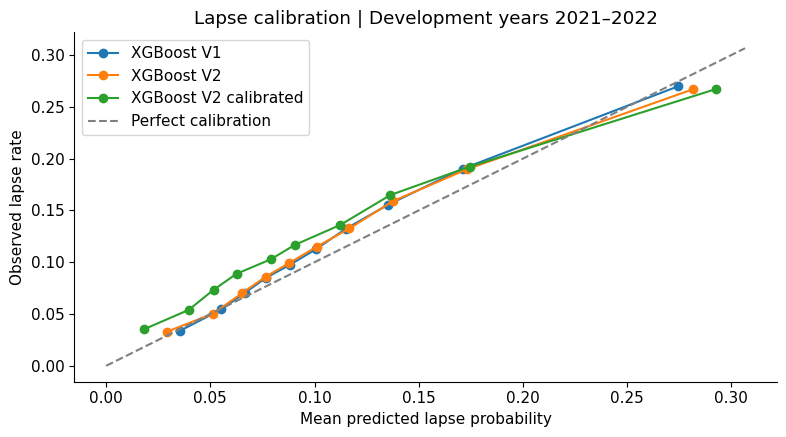

In [31]:
# Plot the calibration of each XGBoost version.
fig, ax = plt.subplots()
for name in ['XGBoost V1', 'XGBoost V2', 'XGBoost V2 calibrated']:
    points = pd.DataFrame({'predicted': pred[MODELS[name]], 'actual': pred.y})
    points['bin'] = (pd.qcut(points.predicted, 10, duplicates='drop')
                     if points.predicted.nunique() > 1 else 0)
    grouped = points.groupby('bin', observed=True)[['predicted', 'actual']].mean()
    ax.plot(grouped.predicted, grouped.actual, marker='o', label=name)

limit = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, limit], [0, limit], '--', color='gray', label='Perfect calibration')
ax.set(title='Lapse calibration | Development years 2021–2022',
       xlabel='Mean predicted lapse probability', ylabel='Observed lapse rate')
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_calibration.png', dpi=150)
plt.show()

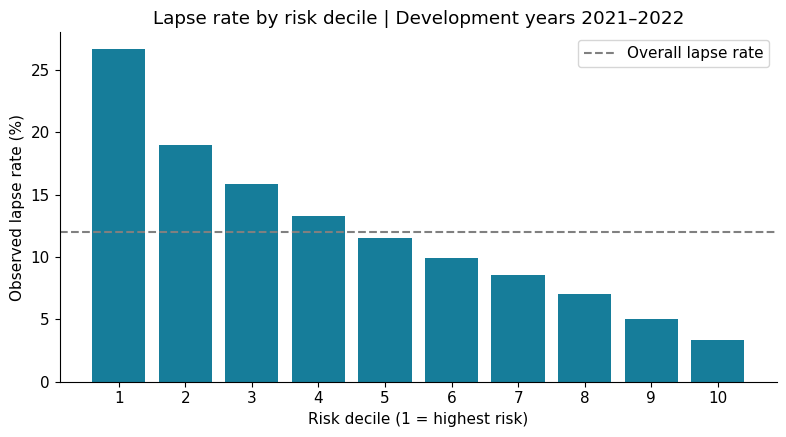

In [32]:
# Plot the observed lapse rate across risk deciles.
fig, ax = plt.subplots()
ax.bar(deciles.index, deciles.actual * 100, color='#167d9a')
ax.axhline(pred.y.mean() * 100, linestyle='--', color='gray', label='Overall lapse rate')
ax.set(title='Lapse rate by risk decile | Development years 2021–2022',
       xlabel='Risk decile (1 = highest risk)', ylabel='Observed lapse rate (%)')
ax.set_xticks(range(1, 11))
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_deciles.png', dpi=150)
plt.show()

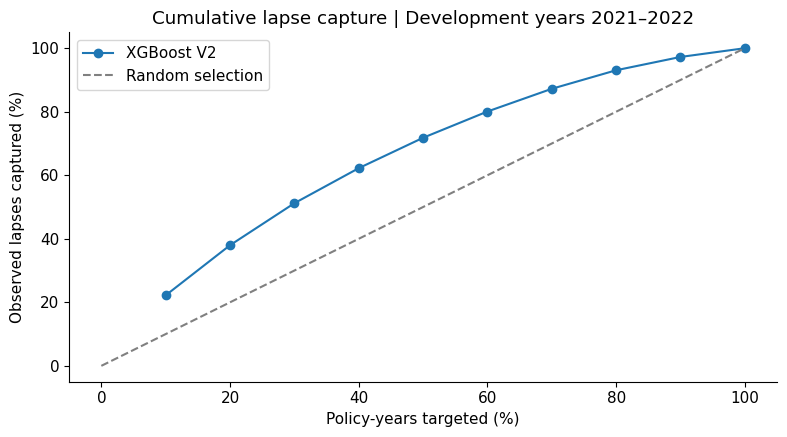

In [33]:
# Plot the cumulative share of observed lapses captured.
fig, ax = plt.subplots()
coverage = np.arange(1, len(deciles) + 1) * 100 / len(deciles)
ax.plot(coverage, deciles.cumulative_capture * 100, marker='o', label=selected_name)
ax.plot([0, 100], [0, 100], '--', color='gray', label='Random selection')
ax.set(title='Cumulative lapse capture | Development years 2021–2022',
       xlabel='Policy-years targeted (%)', ylabel='Observed lapses captured (%)')
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_capture.png', dpi=150)
plt.show()

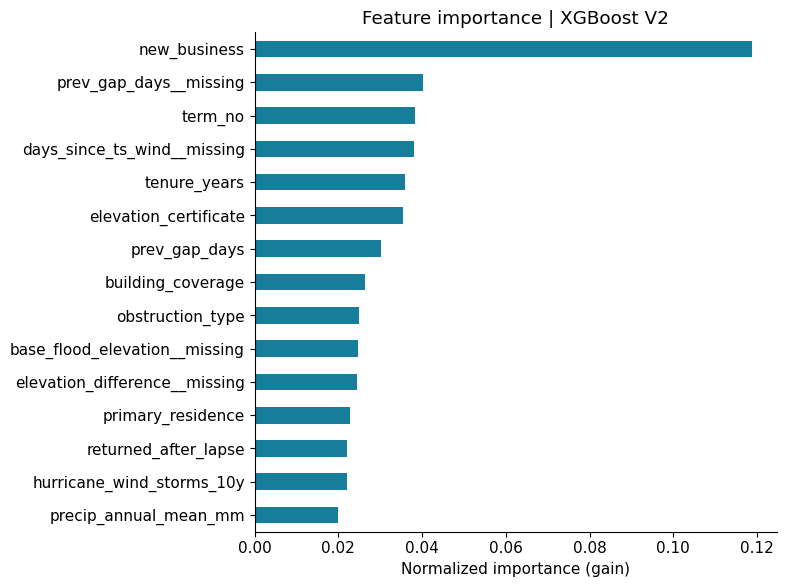

In [34]:
# Plot the features most strongly used by the selected XGBoost model.
chosen_model = starting_model if selected_column == 'p_xgb_start' else tuned_model
importance = pd.Series(chosen_model.feature_importances_, index=chosen_model.get_booster().feature_names)
importance = importance.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importance.head(15).sort_values().plot.barh(ax=ax, color='#167d9a')
ax.set(title=f'Feature importance | {selected_name}', xlabel='Normalized importance (gain)')
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_importance.png', dpi=150)
plt.show()

## 10. Missingness Diagnostics and Sensitivity Analysis
The ACS-missing indicator is retained outside the predictor matrix for diagnostics. Differences between missing and observed groups can reflect both data artifacts and legitimate correlated predictors. A second experiment excludes all seven suspect features using all training rows, the tuned settings, and the same development population. This is a sensitivity check rather than an independently tuned competitor.

In [35]:
# Compare observed and predicted rates by original ACS availability.
missingness = pred.groupby('acs_missing').agg(
    policy_years=('y', 'size'), observed_rate=('y', 'mean'),
    predicted_rate=(selected_column, 'mean')
)
display(missingness.round(4))
print(f'ACS-missing share overall: {pred.acs_missing.mean():.1%}')
print(f'ACS-missing share in the highest-risk decile: {deciles.acs_missing_share.iloc[0]:.1%}')

,policy_years,observed_rate,predicted_rate
acs_missing,,,
False,6272557,0.0847,0.1093
True,833080,0.3878,0.1324


ACS-missing share overall: 11.7%
ACS-missing share in the highest-risk decile: 17.6%


In [36]:
def sensitivity_experiment():
    """Evaluate the tuned configuration after excluding suspect features."""
    features = [f for f in FEATS if f not in RANDOM_COLS]
    state = fit_preprocessor(prep_sample, features=features)
    probe = prep_sample.head(1000)              # the prepared chunks minus the seven features = this preprocessing exactly
    pd.testing.assert_frame_equal(transform_features(probe, state),
                                  transform_features(probe, prep).drop(columns=RANDOM_COLS))
    matrix = all_rows_matrix(drop=RANDOM_COLS)  # every training row, without the seven features
    model = fit_all_rows(best_params, matrix)
    del matrix
    parts = []
    for chunk in range(N_CHUNKS):
        condition = f"hash(CAST(period_id AS VARCHAR) || '{SEED}') % {N_CHUNKS} = {chunk}"
        raw = load_rows('test', condition)
        if raw.empty:
            continue
        probabilities = model.predict_proba(transform_features(raw, state))[:, 1]
        parts.append(pd.DataFrame({'y': raw[TARGET].to_numpy(), 'p': probabilities}))
    scored = pd.concat(parts, ignore_index=True)
    return pd.DataFrame([dict(
        model='Tuned XGBoost with seven suspect features excluded', rows=len(scored),
        log_loss=log_loss(scored.y, scored.p, labels=[0, 1]),
        brier=brier_score_loss(scored.y, scored.p)
    )])

In [37]:
# Record the sensitivity result without changing the selected feature list.
sensitivity = None
if RUN_SENSITIVITY:
    sensitivity = sensitivity_experiment()
    reference = overall[overall.model.eq('XGBoost V2')][['model', 'rows', 'log_loss', 'brier']]
    sensitivity_comparison = pd.concat([reference, sensitivity], ignore_index=True)
    display(sensitivity_comparison.round(5))
    sensitivity_comparison.to_csv(REPORTS / 'lapse_xgb_sensitivity.csv', index=False)

/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

XGBoost training matrix: 26,758,825 rows x 89 predictors built in 0.8 min
trained 200 trees on 26,758,825 rows in 23.2 min


,model,rows,log_loss,brier
0,XGBoost V2,7105637,0.34653,0.10107
1,Tuned XGBoost with seven suspect features excl...,7105637,0.34497,0.10068


## 11. Final Holdout Evaluation
The selected pipeline is frozen using development results before final evaluation. `RUN_FINAL_HOLDOUT` defaults to `False`. When enabled, only the selected XGBoost version and the training-derived benchmarks are evaluated on the final population. Existing final predictions are not overwritten.

In [38]:
# Evaluate the selected pipeline on the final holdout only when enabled.
final_results = None
if RUN_FINAL_HOLDOUT:
    holdout_path = PRED_DIR / 'lapse_xgb_valid.parquet'
    assert not holdout_path.exists(), 'Final predictions already exist; repeated holdout evaluation is blocked.'
    invalid_years = con.sql("""SELECT COUNT(*) FROM lapse_pop
        WHERE split='valid' AND period_year NOT BETWEEN 2023 AND 2024""").fetchall()[0][0]
    assert invalid_years == 0

    final_pred = score_split('valid', only=selected_column)
    final_results = metrics_table(final_pred)
    final_pred.to_parquet(holdout_path, index=False)
    final_results.to_csv(REPORTS / 'lapse_xgb_valid_metrics.csv', index=False)
    display(final_results.round(5))
else:
    print('Final holdout status: not evaluated. Reported model comparisons are development results.')

Final holdout status: not evaluated. Reported model comparisons are development results.


## 12. Results Summary
The summary below is calculated directly from the executed model outputs. Development findings are distinguished from final-holdout evidence.

In [39]:
# Generate the summary from the selected pipeline's actual evaluation scores.
reference_loss = float(overall.loc[overall.model.eq('Base rate'), 'log_loss'].iloc[0])
skill = 1 - float(selected['log_loss']) / reference_loss
capture = float(selected['top_decile_capture'])
calibration_helped = (overall.loc[overall.model.eq('XGBoost V2 calibrated'), 'log_loss'].iloc[0]
                     < overall.loc[overall.model.eq('XGBoost V2'), 'log_loss'].iloc[0])
status = ('Final holdout evaluated; scores are reported in Section 11.' if final_results is not None
          else 'The final holdout has not been evaluated; these findings are development results.')

display(Markdown(f"""**Development-selected pipeline:** {selected_name}.  
**Development period:** 2021–2022, comprising {len(pred):,} eligible policy-years.  
**Log loss:** {selected['log_loss']:.5f}; **Brier score:** {selected['brier']:.5f}.  
**Log-loss skill relative to the training-rate benchmark:** {skill:.1%}.  
**Highest-risk 10%:** captures {capture:.1%} of observed lapses.  
**Calibration:** {'improved' if calibration_helped else 'did not improve'} tuned-model development log loss.  
**Evaluation status:** {status}"""))

**Development-selected pipeline:** XGBoost V2.  
**Development period:** 2021–2022, comprising 7,105,637 eligible policy-years.  
**Log loss:** 0.34653; **Brier score:** 0.10107.  
**Log-loss skill relative to the training-rate benchmark:** 6.0%.  
**Highest-risk 10%:** captures 22.2% of observed lapses.  
**Calibration:** did not improve tuned-model development log loss.  
**Evaluation status:** The final holdout has not been evaluated; these findings are development results.

## 13. Saved Outputs and Reproducibility
Compact reports are saved under `reports/`. Models, preprocessing state, training IDs, and row-level predictions are saved under `data/processed/`. The selected prediction column, sample checksum, feature rules, and software versions identify the evaluated pipeline.

In [40]:
# Save model files and tabular results.
starting_model.save_model(MODEL_DIR / 'xgb_start.json')
tuned_model.save_model(MODEL_DIR / 'xgb_tuned.json')
joblib.dump({'preprocessing': prep, 'calibrator': calibrator},
            MODEL_DIR / 'preprocessing.joblib')

results.to_csv(REPORTS / 'lapse_xgb_test_metrics.csv', index=False)
deciles.to_csv(REPORTS / 'lapse_xgb_test_deciles.csv')
tuning.to_csv(REPORTS / 'lapse_xgb_tuning.csv', index=False)
importance.rename('importance').to_csv(REPORTS / 'lapse_xgb_importance.csv')

### 13.1 Files for notebooks 08a and 08b
Notebooks 08a and 08b evaluate every model the same way, from one saved file per model in `data/processed/models/`. This step saves the selected XGBoost pipeline in that shared format, so 08a/08b can score it on the training, test and validation splits like the logistic regression and the random forest:

- `data/processed/models/lapse_xgb.joblib`: one dict with the preprocessing (`StatePreprocessor` from `src/modeling.py`, which keeps the state learned by `fit_preprocessor` and repeats `transform_features` exactly), the selected model, the feature list and the isotonic calibrator, with `use_calibrator` set when the calibrated version was selected. A check confirms the saved preprocessing gives exactly the same predictors as `transform_features`.
- `reports/lapse_xgb_test_confusion.csv`: confusion matrices of every XGBoost version and the segment rule on the test years, at the same rules as 08a (the riskiest 10%, 20% and 30%, the F1-optimal cut-off, and 0.5). The cut-offs come from the predictions on **every training row**.
- `reports/lapse_xgb_test_auc.csv`: ROC-AUC by period (2021–2022, 2021, 2022).

The training predictions are in-sample for XGBoost (as 06b's are for the logistic regression), so its cut-offs can be slightly higher than they would be on new data; 08a sets its own cut-offs the same way, on every training row.

In [41]:
# Step 13.1 Save the selected pipeline in the shared format of notebooks 08a/08b, with its test confusion and AUC tables
from src.modeling import StatePreprocessor
from src import evaluation as ev

# (a) One joblib dict that 08a/08b can load: preprocessing, model, features, and the calibrator if it was selected
shared_prep = StatePreprocessor(prep, cats=CATS, flags=FLAGS, missing_plan=MISSING_PLAN, seed=SEED)
probe = prep_sample.head(1000)
pd.testing.assert_frame_equal(shared_prep.transform(probe), transform_features(probe, prep))   # the same predictors
selected_model = starting_model if selected_column == 'p_xgb_start' else tuned_model
shared_file = ROOT / 'data/processed/models/lapse_xgb.joblib'
joblib.dump({'preprocess': shared_prep, 'model': selected_model, 'features': FEATS, 'raw_input': True,
             'calibrator': calibrator, 'use_calibrator': selected_column == 'p_xgb_cal'}, shared_file, compress=3)
reloaded_shared = joblib.load(shared_file)
p_check = ev.predict(reloaded_shared, None, probe)
p_now = (calibrator.predict(tuned_model.predict_proba(transform_features(probe, prep))[:, 1])
                      if selected_column == 'p_xgb_cal'
                      else selected_model.predict_proba(transform_features(probe, prep))[:, 1])
np.testing.assert_allclose(p_check, p_now, rtol=1e-6)

# (b) Cut-offs from EVERY training row (the prepared chunks of Section 4.1), confusion matrices on the test years (same rules as 08a)
segment_lookup = np.full((2, 2), base_rate)                          # [new_business, mandatory_purchase] -> training segment rate
for (a, b), rate in segment_map.items():
    segment_lookup[a, b] = rate
parts = []
for k in range(N_CHUNKS):
    frame = read_chunk(k)
    X = frame.drop(columns=EXTRA)
    tuned = tuned_model.predict_proba(X)[:, 1]
    parts.append(pd.DataFrame({
        'y': frame['_y'].to_numpy(),
        'p_xgb_start': starting_model.predict_proba(X)[:, 1].astype('float32'),
        'p_xgb_tuned': tuned.astype('float32'),
        'p_xgb_cal': calibrator.predict(tuned).astype('float32'),
        'p_segment': segment_lookup[frame['_new_business'].clip(0, 1), frame['_mandatory_purchase'].clip(0, 1)].astype('float32')}))
    del frame, X
train_scored = pd.concat(parts, ignore_index=True)
del parts
assert len(train_scored) == TRAIN_ROWS
print(f'cut-offs set on all {len(train_scored):,} training rows')
CM_MODELS = {'Segment rate': 'p_segment', 'XGBoost V1': 'p_xgb_start', 'XGBoost V2': 'p_xgb_tuned',
             'XGBoost V2 calibrated': 'p_xgb_cal'}
confusion = pd.DataFrame([{'model': name, 'rule': rule, **ev.confusion_row(pred.y, pred[col], cut)}
                          for name, col in CM_MODELS.items()
                          for rule, cut in ev.cutoff_rules('lapse', train_scored, col).items()])
confusion.to_csv(REPORTS / 'lapse_xgb_test_confusion.csv', index=False)

# (c) ROC-AUC by period, from the development results of Section 8
auc = results[results.model.isin(CM_MODELS)].pivot(index='model', columns='scope', values='roc_auc')
auc.to_csv(REPORTS / 'lapse_xgb_test_auc.csv')

print(f'saved {shared_file.name} (selected: {selected_name}), lapse_xgb_test_confusion.csv and lapse_xgb_test_auc.csv; '
      'the shared file reproduces the selected predictions')
display(confusion[confusion.rule.eq('riskiest 20% in train')].round(4))
display(auc.round(4))

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

cut-offs set on all 26,758,825 training rows
saved lapse_xgb.joblib (selected: XGBoost V2), lapse_xgb_test_confusion.csv and lapse_xgb_test_auc.csv; the shared file reproduces the selected predictions


,model,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,fpr,lift
1,Segment rate,riskiest 20% in train,0.1598,0.1484,257145,797056,596939,5454497,0.8038,0.2439,0.3011,0.2695,0.1275,2.0294
6,XGBoost V1,riskiest 20% in train,0.1934,0.1078,203259,562863,650825,5688690,0.8292,0.2653,0.2380,0.2509,0.0900,2.2073
11,XGBoost V2,riskiest 20% in train,0.1959,0.1061,198232,555358,655852,5696195,0.8295,0.2631,0.2321,0.2466,0.0888,2.1885
16,XGBoost V2 calibrated,riskiest 20% in train,0.1951,0.1118,206302,587835,647782,5663718,0.8261,0.2598,0.2415,0.2503,0.0940,2.1613


scope,2021,2021-2022,2022
model,,,
Segment rate,0.5578,0.5938,0.6363
XGBoost V1,0.7048,0.6754,0.6416
XGBoost V2,0.7154,0.6767,0.6324
XGBoost V2 calibrated,0.7153,0.6766,0.6322


In [42]:
# Record the complete evaluation configuration.
run = dict(
    target=TARGET, seed=SEED, train_years='2014–2020', development_years='2021–2022',
    holdout_years='2023–August 2024', final_holdout_evaluated=final_results is not None,
    train_rows=TRAIN_ROWS, training_data=f"all {TRAIN_ROWS:,} training rows, 06b's {N_CHUNKS} chunks streamed into a QuantileDMatrix",
    preprocessing_rows=len(prep_sample), tuning_rows=len(tune), sample_origin=sample_origin,
    sample_id_checksum=sample_hash, features=FEATS, suspect_features=RANDOM_COLS,
    imputation='Training-only donors, joint ACS donor, SHA-256 policy-year keys',
    class_weighting='None', parameters=BASE_PARAMS, tuned_parameters=best_params,
    selected_model=selected_name, selected_prediction_column=selected_column,
    calibration='Isotonic on out-of-time training-fold predictions',
    cutoffs=f'riskiest 10/20/30%, F1-optimal and 0.5, set on all {TRAIN_ROWS:,} training rows',
    source_file=str(FEATURES_FILE), source_bytes=FEATURES_FILE.stat().st_size,
    source_mtime_ns=FEATURES_FILE.stat().st_mtime_ns,
    feature_plan_sha256=hashlib.sha256((ROOT / 'docs/feature_plan.csv').read_bytes()).hexdigest(),
    package_versions=versions, development_metrics=overall.to_dict(orient='records')
)
(REPORTS / 'lapse_xgb_run.json').write_text(json.dumps(run, indent=2), encoding='utf-8')

5787

In [43]:
# Confirm that the saved model reproduces the current predictions.
reloaded = xgb.XGBClassifier(enable_categorical=True)
reloaded.load_model(MODEL_DIR / 'xgb_tuned.json')
saved_state = joblib.load(MODEL_DIR / 'preprocessing.joblib')['preprocessing']
probe = prep_sample.head(100)

before = tuned_model.predict_proba(transform_features(probe, prep))[:, 1]
after = reloaded.predict_proba(transform_features(probe, saved_state))[:, 1]
np.testing.assert_allclose(before, after, rtol=1e-6)
print('Model files, reports, and prediction-reload checks completed.')

KEEP_CACHE = True                           # True keeps the prepared training chunks (3-5 GB) for a re-run
if not KEEP_CACHE:
    shutil.rmtree(CACHE_DIR, ignore_errors=True)
    print(f'Removed the temporary training chunks ({CACHE_DIR.relative_to(ROOT)}).')

Model files, reports, and prediction-reload checks completed.


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_34802/3617869139.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

## 14. Limitations
- Reconstructed policy keys and redacted locations introduce linkage and measurement error.
- The target is dominated by non-renewal. Aggregate scores do not establish strong mid-term cancellation prediction.
- ACS features use a later Census snapshot for earlier policy-years. The analysis is retrospective and requires a point-in-time availability review for prospective deployment.
- Stable donor imputation mitigates an obvious missingness pattern but cannot certify the absence of leakage or preserve every relationship with geography and tenure.
- Calibration learned from training-fold predictions may transfer imperfectly to the refitted model and later periods.
- Benchmark comparisons involve complete pipelines. All three models learn from every training row with preprocessing fitted on a 1M-row sample, but encodings, preprocessing, source versions, and scoring IDs must be considered when attributing differences to algorithms.
- Lapse risk identifies high-risk policy-years; it does not estimate the causal effect of retention outreach.

## References
1. [Project repository](https://github.com/jmsebastiancarino/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk): notebooks 03–06B, Random Forest notebook, `docs/feature_plan.csv`, and `docs/population_decisions.md`.
2. [XGBoost documentation](https://xgboost.readthedocs.io/en/stable/): binary classification, categorical support, and model persistence.
3. [scikit-learn probability calibration](https://scikit-learn.org/stable/modules/calibration.html): calibration curves and isotonic calibration.